# REVELA DBSCAN: Objective-Aligned Snapshot Evaluation

Research objective (unchanged): **“3.2 Applying DBSCAN to geolocated Red and Black-flagged records to identify nearby clusters, and examining registry status patterns by barangay and business size.”**

Record-level input comes only from the manually exported, privacy-minimized CSV and its metadata sidecar; no database connection is used. The notebook also reads the repository’s municipal polygon GeoJSON solely to create the requested uniform-polygon Monte Carlo null. It does not change application settings or records. Clusters are of individual geolocated records, not distinct businesses. Registry-status analysis is separate from DBSCAN and cannot be calculated from this point export because application status, business size, and population denominators are intentionally absent.

The snapshot contains 199 Red records and zero Black records. Therefore it is not a two-color evaluation of the objective population. Application parity is **unverified**: the CSV has no application cluster labels and its coordinates were rounded to five decimal places.

The 20 m setting is the historical notebook baseline, not a verified live setting. The repository default is 50 m / MinPts 3; live persisted settings must be recorded independently and are not inferred here. Silhouette describes internal geometry only—not detection accuracy or proof of a real hotspot.

## Input, population, and export limitations

Read `QUERY RESULT.csv` and `QUERY RESULT.metadata.json` from the external `dbscan-export` folder for all record-level data. The CSV schema is intentionally limited to `record_key`, `latitude`, `longitude`, `effective_color`, `source`, `registry_linked`, `barangayID`, and `detected_date`; it must not contain names, addresses, place IDs, reporter IDs, or business IDs. The municipal polygon resource is used only for the Monte Carlo boundary, not as record-level input.

Objective population: effective Red or Black, coordinates required, any source, registry-linked records/business IDs allowed, and no evidence gate. No date or barangay filter is applied in this snapshot. Rows are individual geospatial records, not distinct businesses. The exported `barangayID` is a stored database value and is not verified polygon attribution.

The export is eligible-only. It cannot provide counts excluded before export, exact full-precision duplicate coordinates, extraction timestamp, or application memberships. The sidecar records those as unavailable or unverified rather than inventing them. Live persisted `eps_m`, `min_samples`, and flags must be independently captured to establish which settings the app used.

In [3]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.metrics.pairwise import haversine_distances
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | scikit-learn {sklearn.__version__}")

Python 3.13.3 | pandas 3.0.3 | NumPy 2.5.1 | scikit-learn 1.9.0


The runtime imports below have been checked in this Python 3 kernel. The next cell reads only the manually supplied CSV at the agreed external export path; no credentials or database connection are used.

In [14]:
EXPORT_DIR = Path(r"C:\Users\Mateo\.copilot\session-state\36f14f2a-1997-4913-b952-bc034d86ee3d\files\dbscan-export")
INPUT_PATH = EXPORT_DIR / "QUERY RESULT.csv"
METADATA_PATH = EXPORT_DIR / "QUERY RESULT.metadata.json"
EXPECTED_COLUMNS = {
    "record_key", "latitude", "longitude", "effective_color", "source",
    "registry_linked", "barangayID", "detected_date",
}

if not INPUT_PATH.is_file():
    raise FileNotFoundError(f"Expected manual export was not found: {INPUT_PATH}")

csv_sha256 = hashlib.sha256(INPUT_PATH.read_bytes()).hexdigest()
raw_df = pd.read_csv(
    INPUT_PATH,
    dtype={"record_key": "string", "effective_color": "string", "source": "string"},
    keep_default_na=False,
)
missing_columns = sorted(EXPECTED_COLUMNS.difference(raw_df.columns))
unexpected_columns = sorted(set(raw_df.columns).difference(EXPECTED_COLUMNS))
if missing_columns or unexpected_columns:
    raise ValueError(f"CSV schema mismatch; missing={missing_columns}, unexpected={unexpected_columns}")
if raw_df.empty:
    raise ValueError("The supplied CSV is empty; no data was fabricated or substituted.")

raw_df["record_key"] = raw_df["record_key"].str.strip()
raw_df["effective_color"] = raw_df["effective_color"].str.strip()
raw_df["latitude"] = pd.to_numeric(raw_df["latitude"], errors="coerce")
raw_df["longitude"] = pd.to_numeric(raw_df["longitude"], errors="coerce")
missing_keys = int(raw_df["record_key"].eq("").sum())
duplicate_keys = int(raw_df["record_key"].duplicated().sum())
if missing_keys or duplicate_keys:
    raise ValueError(f"Surrogate keys must be present and unique; missing={missing_keys}, duplicate={duplicate_keys}.")
if raw_df[["latitude", "longitude"]].isna().any().any():
    raise ValueError("CSV has missing or non-numeric coordinates; investigate the export rather than silently dropping rows.")
if not raw_df["latitude"].between(-90, 90).all() or not raw_df["longitude"].between(-180, 180).all():
    raise ValueError("Coordinates must be decimal degrees within valid latitude/longitude ranges.")
if not raw_df["effective_color"].str.casefold().isin({"red", "black"}).all():
    raise ValueError("Objective export must contain only effective Red or Black records.")

raw_df["effective_color"] = raw_df["effective_color"].str.title()
raw_df["registry_linked"] = raw_df["registry_linked"].astype("string").str.casefold().map(
    {"1": True, "true": True, "yes": True, "0": False, "false": False, "no": False}
)
if raw_df["registry_linked"].isna().any():
    raise ValueError("registry_linked must be a recognizable boolean value for every row.")
eligible_df = raw_df.copy()

print(f"CSV: {INPUT_PATH.name} | rows={len(eligible_df):,} | SHA-256={csv_sha256}")
print("Columns validated; no unexpected fields (including names, addresses, place IDs, reporter IDs, or business IDs).")
print("Rows by effective color:", eligible_df["effective_color"].value_counts().to_dict())
print("Rows by source:", eligible_df["source"].replace("", "(blank)").value_counts().to_dict())
print(f"Registry-linked rows: {int(eligible_df['registry_linked'].sum()):,}")
print(f"Duplicate rounded coordinate rows: {int(eligible_df.duplicated(['latitude', 'longitude']).sum()):,}")
print(f"Metadata sidecar present: {METADATA_PATH.is_file()}")

CSV: QUERY RESULT.csv | rows=199 | SHA-256=01b57d7661ebe6e4a5ea64451f993c8a87adccf1947f7a4785f2c92899f01cba
Columns validated; no unexpected fields (including names, addresses, place IDs, reporter IDs, or business IDs).
Rows by effective color: {'Red': 199}
Rows by source: {'detection': 199}
Registry-linked rows: 0
Duplicate rounded coordinate rows: 3
Metadata sidecar present: True


### CSV validation results

The supplied file passed schema and coordinate validation: **199 records**, all effective **Red** from source `detection`; **0 Black** and **0 registry-linked** rows. There are **3 extra rows with repeated coordinates after five-decimal rounding**. This confirms the CSV shape and sample composition only; it does not prove that the extraction included every objective-eligible record. App parity remains unverified.

In [18]:
import subprocess

row_counts_by_color = {
    str(key): int(value)
    for key, value in eligible_df["effective_color"].value_counts().items()
}
row_counts_by_color = {color: row_counts_by_color.get(color, 0) for color in ["Red", "Black"]}
row_counts_by_source = {
    str(key if key else "unknown"): int(value)
    for key, value in eligible_df["source"].fillna("").value_counts().items()
}
rounded_duplicate_extras = int(eligible_df.duplicated(["latitude", "longitude"]).sum())
repo_root = Path(r"C:\REVELA-prod")
commit_result = subprocess.run(
    ["git", "-C", str(repo_root), "rev-parse", "HEAD"],
    check=True,
    capture_output=True,
    text=True,
)
dirty_result = subprocess.run(
    ["git", "-C", str(repo_root), "status", "--porcelain", "--untracked-files=no"],
    check=True,
    capture_output=True,
    text=True,
)
code_commit_record = {
    "value": commit_result.stdout.strip(),
    "status": "head_with_dirty_worktree" if dirty_result.stdout.strip() else "clean_head",
    "working_tree_dirty": bool(dirty_result.stdout.strip()),
    "note": "HEAD is recorded; uncommitted changes, if any, are not represented by the commit hash.",
}

metadata_candidate = {
    "metadata_schema_version": 1,
    "dataset_file": INPUT_PATH.name,
    "metadata_generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "extraction_timestamp_utc": {"value": None, "status": "unavailable_from_csv"},
    "code_commit": code_commit_record,
    "population": {
        "name": "objective",
        "rules": [
            "effective color is Red or Black",
            "latitude and longitude are required",
            "any source is eligible",
            "registry-linked records and business IDs are allowed",
            "no evidence gate, date filter, or barangay filter applied by the objective population",
        ],
        "black_records_in_snapshot": row_counts_by_color["Black"],
    },
    "parameters_used": {
        "eps_m": {"value": None, "source": "unverified_live_setting"},
        "min_samples": {"value": None, "source": "unverified_live_setting"},
        "flags": {"value": ["Red", "Black"], "source": "repository_default_not_verified_live"},
        "repository_defaults_only": {"eps_m": 50, "min_samples": 3},
    },
    "row_counts": {
        "total": int(len(eligible_df)),
        "by_effective_color": row_counts_by_color,
        "by_source": row_counts_by_source,
        "registry_linked": int(eligible_df["registry_linked"].sum()),
        "barangayID_semantics": "stored_database_value_not_polygon_verified",
    },
    "exclusions_by_reason": {
        "counts": None,
        "status": "unavailable_because_csv_contains_only_exported_eligible_rows",
    },
    "duplicate_coordinates": {
        "coordinates_were_rounded_to_decimal_places": 5,
        "duplicate_extra_rows_after_rounding": rounded_duplicate_extras,
        "full_precision_duplicate_count": None,
        "status": "full_precision_duplicate_count_unavailable_from_rounded_csv",
    },
    "library_versions": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scikit_learn": sklearn.__version__,
    },
    "csv_sha256": csv_sha256,
    "application_parity": {
        "status": "unverified",
        "reason": "CSV has no application cluster labels and contains rounded coordinates; live settings and extraction completeness were not independently verified.",
    },
    "validation_limits": [
        "No ground-truth hotspot labels were supplied.",
        "The prior audit noted nine inspection reports, too few for field validation; this CSV does not include them.",
        "No registry-status-by-barangay-by-business-size denominator is present in this point-level export.",
    ],
}

if METADATA_PATH.exists():
    with METADATA_PATH.open("r", encoding="utf-8") as metadata_file:
        metadata = json.load(metadata_file)
    if metadata.get("csv_sha256") != csv_sha256:
        raise ValueError("Existing metadata SHA-256 does not match the CSV; do not overwrite or trust it without review.")
    metadata["code_commit"] = code_commit_record
    metadata["metadata_updated_at_utc"] = datetime.now(timezone.utc).isoformat()
    print(f"Existing metadata validated against CSV SHA-256: {METADATA_PATH.name}")
else:
    metadata = metadata_candidate
    print(f"Created offline metadata sidecar: {METADATA_PATH.name}")

with METADATA_PATH.open("w", encoding="utf-8", newline="\n") as metadata_file:
    json.dump(metadata, metadata_file, indent=2, ensure_ascii=False)
    metadata_file.write("\n")

print("Recorded code commit:", code_commit_record["value"], f"({code_commit_record['status']})")
print("Recorded app parity:", metadata["application_parity"]["status"])
print("Recorded extraction timestamp:", metadata["extraction_timestamp_utc"]["status"])
print("Recorded exclusions:", metadata["exclusions_by_reason"]["status"])

Existing metadata validated against CSV SHA-256: QUERY RESULT.metadata.json
Recorded code commit: fec4d67b9b121011fb51a036398701a5adcc17bd (head_with_dirty_worktree)
Recorded app parity: unverified
Recorded extraction timestamp: unavailable_from_csv
Recorded exclusions: unavailable_because_csv_contains_only_exported_eligible_rows


The sidecar was created or hash-validated from the local CSV, without a database connection. It records the CSV SHA-256, observed row counts, duplicate count at rounded precision, runtime library versions, and population definition. Extraction time, code commit, exclusion counts, live parameter provenance, and app parity remain unavailable/unverified.

In [16]:
EARTH_RADIUS_METERS = 6_371_008.8
HISTORICAL_BASELINE_EPS_M = 20.0
HISTORICAL_BASELINE_MIN_SAMPLES = 3
REPOSITORY_DEFAULT_EPS_M = 50.0
REPOSITORY_DEFAULT_MIN_SAMPLES = 3

record_order = pd.to_numeric(eligible_df["record_key"], errors="coerce")
if record_order.isna().any() or record_order.duplicated().any():
    raise ValueError("record_key must be a unique sequential numeric surrogate to preserve the export's logID order.")
if set(record_order.astype(int)) != set(range(1, len(eligible_df) + 1)):
    raise ValueError("record_key is not sequential 1..N; deterministic ordering cannot be established from this export.")
eligible_df = eligible_df.assign(_stable_order=record_order).sort_values("_stable_order", kind="stable").reset_index(drop=True)
coords_degrees = eligible_df[["latitude", "longitude"]].to_numpy(dtype=float)
coords_radians = np.radians(coords_degrees)
distance_matrix_radians = haversine_distances(coords_radians)


def evaluate_dbscan(eps_meters, min_samples, dataframe=eligible_df):
    coordinates = np.radians(dataframe[["latitude", "longitude"]].to_numpy(dtype=float))
    eps_radians = float(eps_meters) / EARTH_RADIUS_METERS
    labels = DBSCAN(
        eps=eps_radians,
        min_samples=int(min_samples),
        algorithm="ball_tree",
        metric="haversine",
    ).fit_predict(coordinates)
    clustered_mask = labels != -1
    clustered_labels = labels[clustered_mask]
    cluster_sizes = pd.Series(clustered_labels).value_counts().sort_values(ascending=False)
    cluster_count = int(cluster_sizes.size)
    clustered_count = int(clustered_mask.sum())
    noise_count = int((~clustered_mask).sum())
    score = None
    if cluster_count >= 2 and clustered_count > cluster_count:
        if dataframe is eligible_df:
            distances = distance_matrix_radians
        else:
            distances = haversine_distances(coordinates)
        subset_distances = distances[np.ix_(clustered_mask, clustered_mask)]
        score = float(silhouette_score(subset_distances, clustered_labels, metric="precomputed"))
    return {
        "eps_m": float(eps_meters),
        "min_samples": int(min_samples),
        "cluster_count": cluster_count,
        "clustered_records": clustered_count,
        "noise_records": noise_count,
        "clustered_percent": 100 * clustered_count / len(labels),
        "noise_percent": 100 * noise_count / len(labels),
        "silhouette_nonnoise_only": score,
        "largest_cluster_size": int(cluster_sizes.iloc[0]) if cluster_count else 0,
        "cluster_sizes_desc": [int(size) for size in cluster_sizes.tolist()],
        "labels": labels,
    }

historical_baseline = evaluate_dbscan(HISTORICAL_BASELINE_EPS_M, HISTORICAL_BASELINE_MIN_SAMPLES)
repository_default_reference = evaluate_dbscan(REPOSITORY_DEFAULT_EPS_M, REPOSITORY_DEFAULT_MIN_SAMPLES)
app_eps_value = metadata["parameters_used"]["eps_m"]["value"]
app_min_samples_value = metadata["parameters_used"]["min_samples"]["value"]
app_parameters_verified = app_eps_value is not None and app_min_samples_value is not None
app_parameter_result = (
    evaluate_dbscan(app_eps_value, app_min_samples_value)
    if app_parameters_verified else None
)

baseline_rows = [
    {key: value for key, value in historical_baseline.items() if key != "labels"} | {"reference": "historical notebook baseline (20 m / 3)"},
    {key: value for key, value in repository_default_reference.items() if key != "labels"} | {"reference": "repository default only (50 m / 3), not verified live"},
]
if app_parameter_result is not None:
    baseline_rows.append({key: value for key, value in app_parameter_result.items() if key != "labels"} | {"reference": "app parameters from verified metadata"})
display(pd.DataFrame(baseline_rows).set_index("reference"))
print("App parameters:", "verified in metadata" if app_parameters_verified else "UNVERIFIED; no live app-setting run is claimed")
print("Distance: Haversine; input degrees converted to radians; eps converted to radians using R=6,371,008.8 m.")
print("MinPts is scikit-learn min_samples and includes the point itself; order is sequential record_key (export ordered by logID).")

,eps_m,min_samples,cluster_count,clustered_records,noise_records,clustered_percent,noise_percent,silhouette_nonnoise_only,largest_cluster_size,cluster_sizes_desc
reference,,,,,,,,,,
historical notebook baseline (20 m / 3),20.0,3,6,19,180,9.547739,90.452261,0.971732,4,"[4, 3, 3, 3, 3, 3]"
"repository default only (50 m / 3), not verified live",50.0,3,14,66,133,33.165829,66.834171,0.719894,14,"[14, 10, 5, 4, 4, 4, 4, 3, 3, 3, 3, 3, 3, 3]"


App parameters: UNVERIFIED; no live app-setting run is claimed
Distance: Haversine; input degrees converted to radians; eps converted to radians using R=6,371,008.8 m.
MinPts is scikit-learn min_samples and includes the point itself; order is sequential record_key (export ordered by logID).


The 20 m / MinPts 3 result is the historical notebook baseline. The 50 m / MinPts 3 row is only the repository default reference—not a verified live production setting. If the sidecar does not contain persisted settings captured during export, the actual app-parameter row is intentionally omitted. Each evaluation clusters records, not businesses; `min_samples` includes the point itself. Noise is label `-1` and is reported separately. Silhouette, when available, uses non-noise records only.

In [17]:
EPS_VALUES_METERS = list(range(10, 101, 10))
MIN_SAMPLES_VALUES = [3, 4, 5]

grid_rows = []
grid_labels = {}
for min_samples in MIN_SAMPLES_VALUES:
    for eps_meters in EPS_VALUES_METERS:
        result = evaluate_dbscan(eps_meters, min_samples)
        grid_labels[(eps_meters, min_samples)] = result.pop("labels")
        grid_rows.append(result)

grid_df = pd.DataFrame(grid_rows).sort_values(["min_samples", "eps_m"]).reset_index(drop=True)
display(grid_df[[
    "eps_m", "min_samples", "cluster_count", "noise_percent", "clustered_percent",
    "largest_cluster_size", "cluster_sizes_desc", "silhouette_nonnoise_only",
]])
print("Silhouette is not an accuracy metric or a parameter-selection objective; interpret it with noise, coverage, and cluster sizes.")

,eps_m,min_samples,cluster_count,noise_percent,clustered_percent,largest_cluster_size,cluster_sizes_desc,silhouette_nonnoise_only
0,10.0,3,4,93.467337,6.532663,4,"[4, 3, 3, 3]",0.995290
1,20.0,3,6,90.452261,9.547739,4,"[4, 3, 3, 3, 3, 3]",0.971732
2,30.0,3,11,80.904523,19.095477,5,"[5, 4, 4, 4, 3, 3, 3, 3, 3, 3, 3]",0.845933
3,40.0,3,13,73.869347,26.130653,9,"[9, 7, 5, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3]",0.760304
4,50.0,3,14,66.834171,33.165829,14,"[14, 10, 5, 4, 4, 4, 4, 3, 3, 3, 3, 3, 3, 3]",0.719894
5,60.0,3,13,60.301508,39.698492,17,"[17, 10, 9, 7, 6, 5, 5, 4, 4, 3, 3, 3, 3]",0.733292
6,70.0,3,17,50.251256,49.748744,17,"[17, 12, 9, 7, 7, 7, 6, 5, 4, 4, 3, 3, 3, 3, 3, 3, 3]",0.723658
7,80.0,3,23,38.190955,61.809045,17,"[17, 12, 9, 7, 7, 7, 6, 5, 5, 5, 4, 4, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3]",0.687604
8,90.0,3,25,31.155779,68.844221,17,"[17, 12, 12, 11, 7, 7, 6, 5, 5, 5, 4, 4, 4, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]",0.633097
9,100.0,3,24,26.633166,73.366834,33,"[33, 15, 12, 7, 7, 6, 5, 5, 5, 5, 5, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]",0.607979


Silhouette is not an accuracy metric or a parameter-selection objective; interpret it with noise, coverage, and cluster sizes.


This grid compares 10–100 m in 10 m steps with MinPts 3–5 on the same ordered snapshot. Coverage is the share assigned to non-noise clusters; noise is the share labeled `-1`; cluster sizes count point records. Silhouette measures geometric cohesion/separation only among assigned records, excluding noise, and does not validate real-world hotspots. No setting is selected solely because it has the highest score.

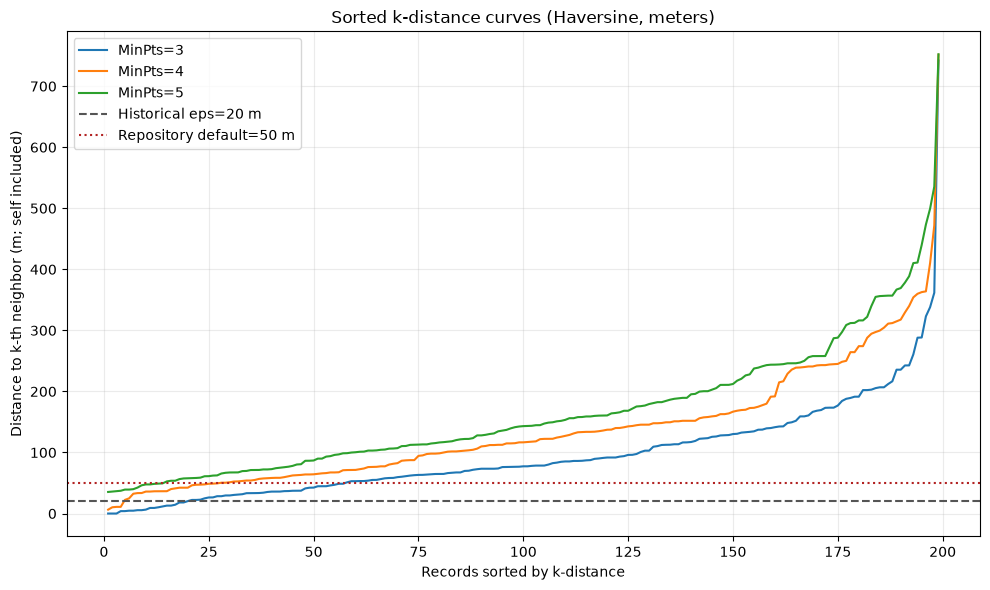

K-distance elbows are heuristic aids, not an automatic eps selector. Review local density variation and stability as well.


In [9]:
k_distance_rows = []
for min_samples in MIN_SAMPLES_VALUES:
    neighbors = NearestNeighbors(
        n_neighbors=min_samples,
        algorithm="ball_tree",
        metric="haversine",
    ).fit(coords_radians)
    neighbor_distances, _ = neighbors.kneighbors(coords_radians)
    sorted_k_distances_m = np.sort(neighbor_distances[:, -1] * EARTH_RADIUS_METERS)
    k_distance_rows.append((min_samples, sorted_k_distances_m))

fig, ax = plt.subplots(figsize=(10, 6))
for min_samples, distances_m in k_distance_rows:
    ax.plot(np.arange(1, len(distances_m) + 1), distances_m, label=f"MinPts={min_samples}")
ax.axhline(HISTORICAL_BASELINE_EPS_M, color="#555555", linestyle="--", label="Historical eps=20 m")
ax.axhline(REPOSITORY_DEFAULT_EPS_M, color="#b22222", linestyle=":", label="Repository default=50 m")
ax.set_title("Sorted k-distance curves (Haversine, meters)")
ax.set_xlabel("Records sorted by k-distance")
ax.set_ylabel("Distance to k-th neighbor (m; self included)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

print("K-distance elbows are heuristic aids, not an automatic eps selector. Review local density variation and stability as well.")

The k-distance curve shows each record’s distance to its MinPts-th neighbor (including itself), sorted from small to large. A bend can suggest a transition in density, but it does not establish one universally correct radius. Evaluate this alongside how memberships and noise change across the grid.

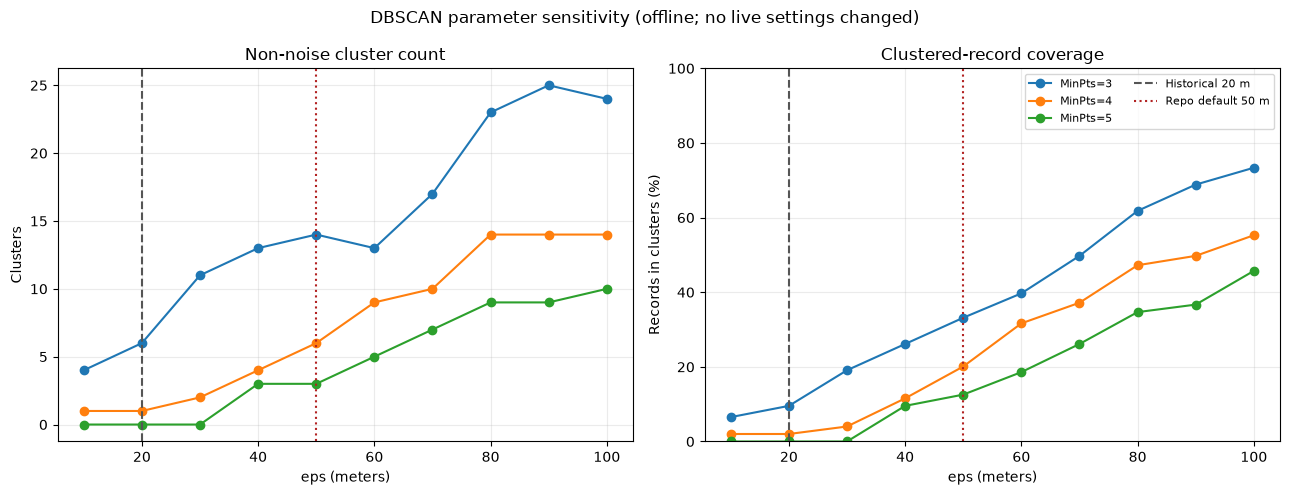

,min_samples,eps_pair_m,ARI_all_records,noise_membership_jaccard
0,3,10-20,0.788619,0.967742
1,3,20-30,0.593291,0.894444
2,3,30-40,0.772005,0.913043
3,3,40-50,0.798153,0.904762
4,3,50-60,0.821683,0.902256
5,3,60-70,0.745702,0.833333
6,3,70-80,0.692624,0.760000
7,3,80-90,0.790879,0.815789
8,3,90-100,0.783024,0.854839
9,4,10-20,1.000000,1.000000


ARI compares full partitions; noise Jaccard compares which records are noise. Neither is field validation or detection accuracy.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for min_samples in MIN_SAMPLES_VALUES:
    subset = grid_df.loc[grid_df["min_samples"].eq(min_samples)].sort_values("eps_m")
    axes[0].plot(subset["eps_m"], subset["cluster_count"], marker="o", label=f"MinPts={min_samples}")
    axes[1].plot(subset["eps_m"], subset["clustered_percent"], marker="o", label=f"MinPts={min_samples}")
for ax in axes:
    ax.axvline(HISTORICAL_BASELINE_EPS_M, color="#555555", linestyle="--", label="Historical 20 m")
    ax.axvline(REPOSITORY_DEFAULT_EPS_M, color="#b22222", linestyle=":", label="Repo default 50 m")
    ax.set_xlabel("eps (meters)")
    ax.grid(alpha=0.25)
axes[0].set_title("Non-noise cluster count")
axes[0].set_ylabel("Clusters")
axes[1].set_title("Clustered-record coverage")
axes[1].set_ylabel("Records in clusters (%)")
axes[1].set_ylim(0, 100)
axes[1].legend(fontsize=8, ncol=2)
fig.suptitle("DBSCAN parameter sensitivity (offline; no live settings changed)")
fig.tight_layout()
plt.show()

stability_rows = []
for min_samples in MIN_SAMPLES_VALUES:
    for eps_left, eps_right in zip(EPS_VALUES_METERS[:-1], EPS_VALUES_METERS[1:]):
        left_labels = grid_labels[(eps_left, min_samples)]
        right_labels = grid_labels[(eps_right, min_samples)]
        left_noise = left_labels == -1
        right_noise = right_labels == -1
        union_noise = int(np.logical_or(left_noise, right_noise).sum())
        noise_jaccard = (
            float(np.logical_and(left_noise, right_noise).sum()) / union_noise
            if union_noise else 1.0
        )
        stability_rows.append({
            "min_samples": min_samples,
            "eps_pair_m": f"{eps_left}-{eps_right}",
            "ARI_all_records": float(adjusted_rand_score(left_labels, right_labels)),
            "noise_membership_jaccard": noise_jaccard,
        })
stability_df = pd.DataFrame(stability_rows)
display(stability_df)
print("ARI compares full partitions; noise Jaccard compares which records are noise. Neither is field validation or detection accuracy.")

The plots show the trade-off as eps grows: cluster counts and coverage can both change non-monotonically because DBSCAN merges and expands density-connected groups. Adjacent-grid ARI summarizes partition agreement, while noise Jaccard summarizes noise-set overlap. These are stability descriptions, not evidence that a cluster is a true hotspot. The line charts use geographic coordinates directly rather than PCA because the analysis has only two spatial features and preserving meters-on-Earth meaning is more interpretable.

In [11]:
deduplicated_df = eligible_df.drop_duplicates(["latitude", "longitude"], keep="first").copy()
duplicate_sensitivity_rows = []
for label, frame in [("all rounded-coordinate records", eligible_df), ("one record per rounded coordinate", deduplicated_df)]:
    for eps_meters, min_samples, reference in [
        (HISTORICAL_BASELINE_EPS_M, HISTORICAL_BASELINE_MIN_SAMPLES, "historical 20 m / 3"),
        (REPOSITORY_DEFAULT_EPS_M, REPOSITORY_DEFAULT_MIN_SAMPLES, "repository default reference 50 m / 3"),
    ]:
        result = evaluate_dbscan(eps_meters, min_samples, dataframe=frame)
        duplicate_sensitivity_rows.append({
            "coordinate_treatment": label,
            "reference": reference,
            "n_records": len(frame),
            "cluster_count": result["cluster_count"],
            "noise_records": result["noise_records"],
            "coverage_percent": result["clustered_percent"],
            "cluster_sizes_desc": result["cluster_sizes_desc"],
        })
duplicate_sensitivity_df = pd.DataFrame(duplicate_sensitivity_rows)
display(duplicate_sensitivity_df)

print("Legacy evidence-gate sensitivity: NOT COMPUTABLE from this export.")
print("The export lacks placeID, reporter ID, stored Orange evidence, and inspection-report linkage, and does not include the seven records described by the old notebook.")
print("Do not apply the old evidence gate to the objective population; it is not part of the current objective eligibility rule.")

,coordinate_treatment,reference,n_records,cluster_count,noise_records,coverage_percent,cluster_sizes_desc
0,all rounded-coordinate records,historical 20 m / 3,199,6,180,9.547739,"[4, 3, 3, 3, 3, 3]"
1,all rounded-coordinate records,repository default reference 50 m / 3,199,14,133,33.165829,"[14, 10, 5, 4, 4, 4, 4, 3, 3, 3, 3, 3, 3, 3]"
2,one record per rounded coordinate,historical 20 m / 3,196,5,180,8.163265,"[4, 3, 3, 3, 3]"
3,one record per rounded coordinate,repository default reference 50 m / 3,196,13,133,32.142857,"[14, 10, 5, 4, 4, 4, 4, 3, 3, 3, 3, 3, 3]"


Legacy evidence-gate sensitivity: NOT COMPUTABLE from this export.
The export lacks placeID, reporter ID, stored Orange evidence, and inspection-report linkage, and does not include the seven records described by the old notebook.
Do not apply the old evidence gate to the objective population; it is not part of the current objective eligibility rule.


The duplicate sensitivity compares all 199 records with one representative per repeated rounded coordinate; it is not a full-precision duplicate test because coordinates were rounded in the export. The old notebook’s “seven records failing an evidence rule” cannot be recreated from this CSV: the relevant evidence columns and omitted rows are unavailable. That legacy-gate sensitivity is explicitly unavailable, not approximated.

,eps_m,null_model,runs,observed_clusters,simulated_cluster_count_median,simulated_cluster_count_95pct,observed_noise_percent,simulated_noise_percent_median,simulated_noise_percent_95pct,empirical_upper_tail_probability_cluster_count
0,20.0,uniform points in municipal polygon,1000,6,0.0,"[0.0, 0.0]",90.452261,100.0,"[100.0, 100.0]",0.000999
1,50.0,uniform points in municipal polygon,1000,14,0.0,"[0.0, 2.0]",66.834171,100.0,"[96.98492462311557, 100.0]",0.000999


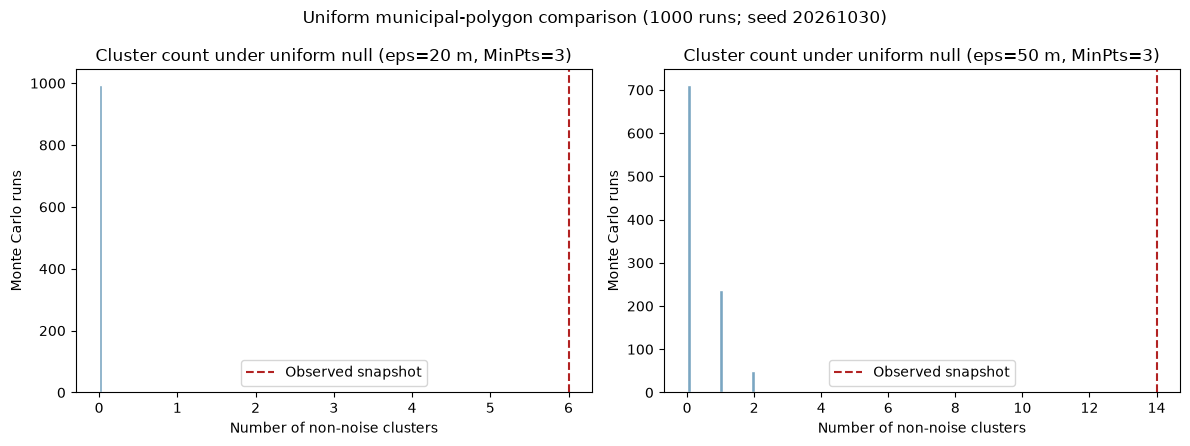

Null-model limits: uniform sampling ignores population density, reporting effort, road access, land use, and measurement bias; this comparison is exploratory, not proof of hotspot detection.


In [12]:
import json as json_module
from shapely.geometry import Point, shape
from shapely.ops import unary_union
from shapely.prepared import prep

POLYGON_PATH = Path(r"C:\REVELA-prod\revela_backend\api\utils\mataasnakahoy.json")
if not POLYGON_PATH.is_file():
    raise FileNotFoundError(f"Municipal polygon file needed for Monte Carlo sampling is unavailable: {POLYGON_PATH}")
with POLYGON_PATH.open("r", encoding="utf-8") as polygon_file:
    polygon_geojson = json_module.load(polygon_file)
municipality = unary_union([shape(feature["geometry"]) for feature in polygon_geojson["features"]])
prepared_municipality = prep(municipality)
min_lon, min_lat, max_lon, max_lat = municipality.bounds

MONTE_CARLO_RUNS = 1000
MONTE_CARLO_SEED = 20261030
monte_carlo_rng = np.random.default_rng(MONTE_CARLO_SEED)
monte_carlo_eps = [HISTORICAL_BASELINE_EPS_M, REPOSITORY_DEFAULT_EPS_M]
observed_results = {
    HISTORICAL_BASELINE_EPS_M: historical_baseline,
    REPOSITORY_DEFAULT_EPS_M: repository_default_reference,
}
monte_carlo_counts = {eps: [] for eps in monte_carlo_eps}
monte_carlo_noise = {eps: [] for eps in monte_carlo_eps}

for run_index in range(MONTE_CARLO_RUNS):
    sampled_points = []
    while len(sampled_points) < len(eligible_df):
        needed = len(eligible_df) - len(sampled_points)
        batch_size = max(64, needed * 2)
        random_lons = monte_carlo_rng.uniform(min_lon, max_lon, batch_size)
        random_lats = monte_carlo_rng.uniform(min_lat, max_lat, batch_size)
        for longitude, latitude in zip(random_lons, random_lats):
            if prepared_municipality.contains(Point(float(longitude), float(latitude))):
                sampled_points.append((float(latitude), float(longitude)))
                if len(sampled_points) == len(eligible_df):
                    break
    random_coords_radians = np.radians(np.asarray(sampled_points, dtype=float))
    for eps_meters in monte_carlo_eps:
        random_labels = DBSCAN(
            eps=eps_meters / EARTH_RADIUS_METERS,
            min_samples=HISTORICAL_BASELINE_MIN_SAMPLES,
            algorithm="ball_tree",
            metric="haversine",
        ).fit_predict(random_coords_radians)
        monte_carlo_counts[eps_meters].append(len(set(random_labels) - {-1}))
        monte_carlo_noise[eps_meters].append(float(np.mean(random_labels == -1) * 100))

monte_carlo_summary_rows = []
for eps_meters in monte_carlo_eps:
    simulated_cluster_counts = np.asarray(monte_carlo_counts[eps_meters])
    simulated_noise = np.asarray(monte_carlo_noise[eps_meters])
    observed = observed_results[eps_meters]
    upper_tail_p = (1 + int(np.sum(simulated_cluster_counts >= observed["cluster_count"]))) / (MONTE_CARLO_RUNS + 1)
    monte_carlo_summary_rows.append({
        "eps_m": eps_meters,
        "null_model": "uniform points in municipal polygon",
        "runs": MONTE_CARLO_RUNS,
        "observed_clusters": observed["cluster_count"],
        "simulated_cluster_count_median": float(np.median(simulated_cluster_counts)),
        "simulated_cluster_count_95pct": [float(v) for v in np.quantile(simulated_cluster_counts, [0.025, 0.975])],
        "observed_noise_percent": observed["noise_percent"],
        "simulated_noise_percent_median": float(np.median(simulated_noise)),
        "simulated_noise_percent_95pct": [float(v) for v in np.quantile(simulated_noise, [0.025, 0.975])],
        "empirical_upper_tail_probability_cluster_count": float(upper_tail_p),
    })
monte_carlo_summary = pd.DataFrame(monte_carlo_summary_rows)
display(monte_carlo_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, eps_meters in zip(axes, monte_carlo_eps):
    ax.hist(monte_carlo_counts[eps_meters], bins=25, color="#7aa6c2", edgecolor="white")
    ax.axvline(observed_results[eps_meters]["cluster_count"], color="#b22222", linestyle="--", label="Observed snapshot")
    ax.set_title(f"Cluster count under uniform null (eps={eps_meters:.0f} m, MinPts=3)")
    ax.set_xlabel("Number of non-noise clusters")
    ax.set_ylabel("Monte Carlo runs")
    ax.legend()
fig.suptitle(f"Uniform municipal-polygon comparison ({MONTE_CARLO_RUNS} runs; seed {MONTE_CARLO_SEED})")
fig.tight_layout()
plt.show()

print("Null-model limits: uniform sampling ignores population density, reporting effort, road access, land use, and measurement bias; this comparison is exploratory, not proof of hotspot detection.")

In [19]:
polygon_sha256 = hashlib.sha256(POLYGON_PATH.read_bytes()).hexdigest()
metadata["monte_carlo"] = {
    "runs": MONTE_CARLO_RUNS,
    "seed": MONTE_CARLO_SEED,
    "eps_m_values": monte_carlo_eps,
    "min_samples": HISTORICAL_BASELINE_MIN_SAMPLES,
    "sample_count_per_run": int(len(eligible_df)),
    "spatial_null": "uniform longitude/latitude samples inside the union of municipal barangay polygons",
    "polygon_resource": "revela_backend/api/utils/mataasnakahoy.json",
    "polygon_sha256": polygon_sha256,
    "limitations": "uniform null ignores population density, reporting effort, road access, land use, and measurement bias",
}
with METADATA_PATH.open("w", encoding="utf-8", newline="\n") as metadata_file:
    json.dump(metadata, metadata_file, indent=2, ensure_ascii=False)
    metadata_file.write("\n")
print("Saved Monte Carlo reproducibility details to metadata sidecar.")
print("Municipal polygon SHA-256:", polygon_sha256)

Saved Monte Carlo reproducibility details to metadata sidecar.
Municipal polygon SHA-256: c49f51d8eb337aa4bc4dab9e0abcc2d5cb3c9f321ff85b19327e01acb291ade2


The sidecar now also records the 1,000-run Monte Carlo seed, point count, parameter values, and SHA-256 of the repository polygon resource used. This boundary file is an analysis resource only; all observed record attributes still come only from the CSV and metadata.

The 1,000-run comparison is complete for both the historical 20 m baseline and the 50 m repository-default reference. The synthetic spatial null is uniform within the repository municipal polygon and uses the same point count; it should not be read as a formal significance test or as validation of detected hotspots.

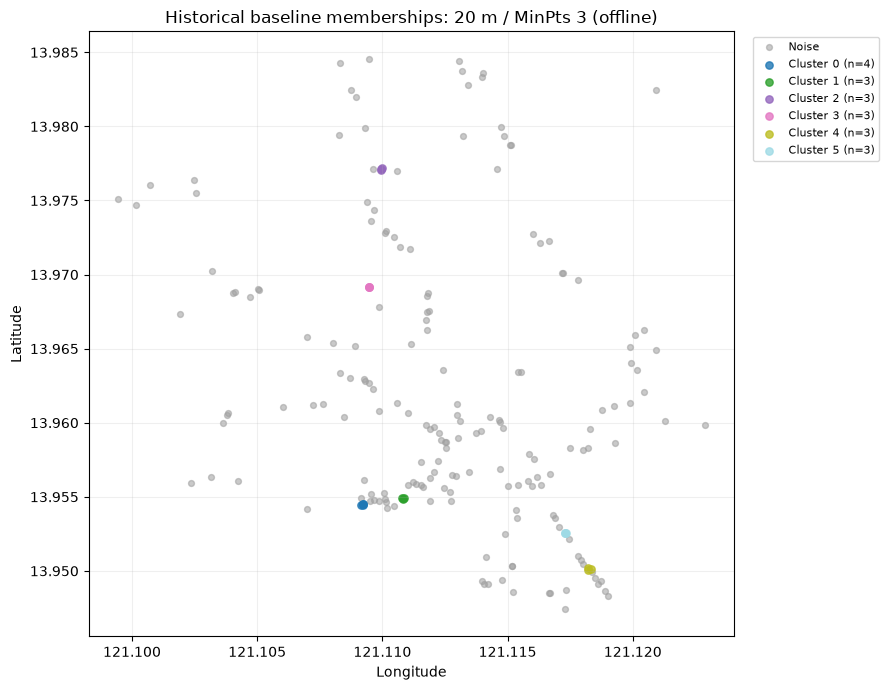

APP PARITY: UNVERIFIED — no per-record app cluster labels were included in CSV or metadata.
Registry status × barangay × business-size analysis: NOT AVAILABLE in this point-level export; required registry denominator and categories are absent.


In [13]:
baseline_labels = historical_baseline["labels"]
map_df = eligible_df.copy()
map_df["cluster_label"] = baseline_labels

fig, ax = plt.subplots(figsize=(9, 7))
cluster_ids = sorted(label for label in np.unique(baseline_labels) if label != -1)
if np.any(baseline_labels == -1):
    noise_rows = map_df.loc[map_df["cluster_label"].eq(-1)]
    ax.scatter(noise_rows["longitude"], noise_rows["latitude"], s=18, color="#9e9e9e", alpha=0.55, label="Noise")
cluster_colors = plt.cm.tab20(np.linspace(0, 1, max(len(cluster_ids), 1)))
for color, cluster_id in zip(cluster_colors, cluster_ids):
    members = map_df.loc[map_df["cluster_label"].eq(cluster_id)]
    ax.scatter(members["longitude"], members["latitude"], s=28, alpha=0.8, color=color, label=f"Cluster {cluster_id} (n={len(members)})")
ax.set_title("Historical baseline memberships: 20 m / MinPts 3 (offline)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

app_cluster_labels = metadata.get("application_cluster_labels")
if app_cluster_labels is None:
    print("APP PARITY: UNVERIFIED — no per-record app cluster labels were included in CSV or metadata.")
else:
    if len(app_cluster_labels) != len(baseline_labels):
        raise ValueError("App parity failed: application labels length differs from exported record count.")
    app_cluster_labels = np.asarray(app_cluster_labels, dtype=int)
    observed_noise = baseline_labels == -1
    app_noise = app_cluster_labels == -1
    if not np.array_equal(observed_noise, app_noise):
        raise AssertionError("App parity failed: noise membership differs from the application output.")
    predicted_pairs = baseline_labels[:, None] == baseline_labels[None, :]
    app_pairs = app_cluster_labels[:, None] == app_cluster_labels[None, :]
    same_membership = np.array_equal(predicted_pairs, app_pairs)
    if not same_membership:
        raise AssertionError("App parity failed: cluster membership differs (cluster labels may be permuted).")
    print("APP PARITY: VERIFIED — cluster membership and noise set match, ignoring label permutations.")

print("Registry status × barangay × business-size analysis: NOT AVAILABLE in this point-level export; required registry denominator and categories are absent.")

The map is a lon/lat view of the 20 m historical-baseline labels; clustering is not constrained by barangay boundaries. The application’s membership labels are absent from this CSV, so the parity branch correctly reports unverified. A future parity check requires per-record app labels keyed in the same record order and the actual `parameters_used` from the same snapshot.

## Interpretation limits

- This is a one-snapshot, Red-only point analysis: the supplied file has **199 effective Red records and 0 Black records**. It cannot answer how the two-color objective behaves when Black records are present.
- There are no ground-truth hotspot labels or field-confirmed outcomes in the export. A prior audit noted nine inspection reports, too few for validation; this notebook does not treat them as labels.
- Silhouette is computed only for non-noise points when at least two clusters exist. It measures within-cluster versus between-cluster geometric separation; it is not precision, recall, detection accuracy, or proof of a real hotspot.
- The municipal uniform-point Monte Carlo comparison is an intentionally simple spatial null. It ignores population/business density, reporting and inspection effort, roads, land use, and other spatial biases.
- The CSV’s `barangayID` is a stored value, not polygon-attributed here. This export lacks `applicationStatus`, `businessSize`, and denominators, so registry-status patterns by barangay/business size require a separate appropriately defined registry dataset.
- No production setting was changed. The 50 m / MinPts 3 result is only the repository-default reference; live settings and extraction time remain unverified.

### Q&A

- **Does this snapshot evaluate both effective Red and Black records?** No. It contains 199 Red and zero Black rows, so results describe only the supplied Red snapshot.
- **Is app parity verified?** No. The export has no application memberships or verified live settings; parity is explicitly unverified.
- **Does a high Silhouette score show detection accuracy or a real hotspot?** No. It measures geometric separation among non-noise records only.
- **Does this export support registry status by barangay and business size?** No. It omits application status, business size, and the registry denominator needed for those rates.

### Data Analysis Key Findings

- At the historical 20 m / MinPts 3 baseline, DBSCAN found **6 clusters**, assigned **19/199 records (9.5%)**, and labeled **180/199 (90.5%)** as noise; the largest cluster had 4 records. Silhouette was **0.972** among non-noise points only.
- At the repository-default reference of 50 m / MinPts 3, it found **14 clusters**, assigned **66/199 (33.2%)**, and labeled **133/199 (66.8%)** as noise; the largest cluster had 14 records. This is not a verified live setting.
- Deduplicating the three extra rows with identical rounded coordinates changed the 20 m result from 6 to 5 clusters (19 to 16 clustered records) and the 50 m result from 14 to 13 clusters (66 to 63 clustered records). Rounded-coordinate duplicates may not equal full-precision duplicates.
- In 1,000 uniform-polygon simulations, median cluster count was 0 at 20 m and 0 at 50 m (50 m 95th percentile: 2), versus observed counts 6 and 14. This is an exploratory comparison to a simplistic null, not validation or evidence of real hotspots.

### Insights or Next Steps

- Export effective Black records with the same objective rules, and capture extraction timestamp plus actual app `parameters_used`; then rerun the analysis and parity check against per-record application memberships.
- Use a separate registry-level dataset with status, business size, barangay assignment, and explicit denominators to analyze registry-status patterns; obtain field-reviewed labels before making detection-quality claims.